In [1]:
import numpy as np
import pandas as pd
import networkx as nx

%matplotlib widget

from matplotlib.colors import PowerNorm
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import BoundaryNorm
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection, PathCollection


In [2]:
nodes = pd.read_csv("nodes.csv")
edges = pd.read_csv("edges.csv")

In [3]:
# --- build graph ---
G = nx.Graph()
for r in nodes.itertuples():
    G.add_node(r.id, label=r.label, type=r.type, state=r.state,
               accidents=r.accidents)
for r in edges.itertuples():
    G.add_edge(r.source, r.target, type=r.type, weight=r.weight)

states = [n for n, d in G.nodes(data=True) if d["type"] == "state"]
cities = [n for n, d in G.nodes(data=True) if d["type"] == "city"]
border_edges = [(u, v) for u, v, d in G.edges(data=True) if d["type"] == "border"]
contain_edges = [(u, v) for u, v, d in G.edges(data=True) if d["type"] == "contains"]

In [4]:
def add_interaction(fig, ax, pos):
    ns = len(states)
    state_idx = {s: i for i, s in enumerate(states)}
    rank = {s: i + 1 for i, s in enumerate(sorted(states, key=lambda s: -G.nodes[s]["accidents"]))}
    nbrs = {s: [v for v in G[s] if G.edges[s, v]["type"] == "border"] for s in states}
    city_state = np.array([state_idx[G.nodes[c]["state"]] for c in cities])

    # ---- find the artists your drawing code already created ----
    n_state = n_city = e_border = e_contain = None
    for coll in ax.collections:
        if isinstance(coll, PathCollection):
            n = len(coll.get_offsets())
            if n == len(states): n_state = coll
            elif n == len(cities): n_city = coll
        elif isinstance(coll, LineCollection):
            n = len(coll.get_segments())
            if n == len(border_edges): e_border = coll
            elif n == len(contain_edges): e_contain = coll
    if None in (n_state, n_city, e_border, e_contain):
        raise RuntimeError("Could not find all node/edge collections on ax; "
                           "call add_interaction after the drawing code, on the same ax.")

    # ---- labels: match each text to its node by position ----
    key = lambda p: (round(float(p[0]), 6), round(float(p[1]), 6))
    at = {}
    for node in states + cities:
        at.setdefault(key(pos[node]), node)
    labels = [(at[key(t.get_position())], t) for t in ax.texts if key(t.get_position()) in at]

    # ---- snapshot colours; bake any collection-level alpha into the per-node colours ----
    def snap(coll, n):
        return (np.broadcast_to(coll.get_facecolor(), (n, 4)).copy(),
                np.broadcast_to(coll.get_edgecolor(), (n, 4)).copy())

    fc_s, ec_s = snap(n_state, ns)
    fc_c, ec_c = snap(n_city, len(cities))
    for coll, fc, ec in ((n_state, fc_s, ec_s), (n_city, fc_c, ec_c)):
        coll.set_alpha(None)                 # otherwise it would override per-node alpha
        coll.set_facecolor(fc)
        coll.set_edgecolor(ec)

    a_border = e_border.get_alpha() if e_border.get_alpha() is not None else 1
    a_contain = e_contain.get_alpha() if e_contain.get_alpha() is not None else 1

    XY = np.array([pos[n] for n in states + cities])
    sizes = np.concatenate([np.broadcast_to(n_state.get_sizes(), (ns,)),
                            np.broadcast_to(n_city.get_sizes(), (len(cities),))])
    radius_pt = np.sqrt(sizes) / 2

    # ---- overlays ----
    hl_b = LineCollection([], colors="#d62728", linewidths=3, zorder=1.5)
    hl_c = LineCollection([], colors="#222222", linewidths=0.9, alpha=0.6, zorder=1.5)
    ax.add_collection(hl_b)
    ax.add_collection(hl_c)

    hint = ("Click a state or city to highlight it and its neighbours "
            "(click empty space or press Esc to clear)")
    info = fig.text(0.5, 0.01, hint, ha="center", fontsize=11)
    tip = ax.annotate("", xy=(0, 0), xytext=(14, 14), textcoords="offset points",
                      fontsize=9, zorder=10,
                      bbox=dict(boxstyle="round", fc="white", ec="#444", alpha=0.95))
    tip.set_visible(False)
    st = {"sel": None, "city": None, "hover": None}

    def find_node(event):
        pix = ax.transData.transform(XY)
        d = np.hypot(pix[:, 0] - event.x, pix[:, 1] - event.y)
        r = np.maximum(radius_pt * fig.dpi / 72, 5)
        hit = np.where(d <= r)[0]
        if hit.size == 0:
            return None
        sh = hit[hit < ns]                   # hubs sit on top of cities
        pool = sh if sh.size else hit
        return pool[np.argmin(d[pool] / r[pool])]

    def tip_text(i):
        if i < ns:
            s = states[i]
            return (f"{s}\n{G.nodes[s]['accidents']:,} accidents\n"
                    f"rank {rank[s]} of {len(states)}\n"
                    f"borders: {', '.join(sorted(nbrs[s])) or '-'}")
        n = G.nodes[cities[i - ns]]
        return f"{n['label']}, {n['state']}\n{n['accidents']:,} accidents\n{n['share']:.1%} of the state"

    def on_move(event):
        if event.inaxes is not ax:
            if st["hover"] is not None:
                st["hover"] = None
                tip.set_visible(False)
                fig.canvas.draw_idle()
            return
        i = find_node(event)
        if i == st["hover"]:
            return
        st["hover"] = i
        if i is None:
            tip.set_visible(False)
        else:
            tip.xy = XY[i]
            tip.set_text(tip_text(i))
            tip.set_visible(True)
        fig.canvas.draw_idle()

    def highlight(s, c=None):
        st["sel"], st["city"] = s, c
        sname = states[s]
        nb = [state_idx[v] for v in nbrs[sname]]

        keep_s = np.zeros(ns, bool)
        keep_s[[s] + nb] = True
        a, b = fc_s.copy(), ec_s.copy()
        a[~keep_s, 3] = 0.15
        b[~keep_s, 3] = 0.15
        n_state.set_facecolor(a); n_state.set_edgecolor(b)

        keep_c = city_state == s
        a, b = fc_c.copy(), ec_c.copy()
        a[~keep_c, 3] = 0.08
        b[~keep_c, 3] = 0.08
        if c is not None:                    # clicked a city: soften its siblings
            sib = keep_c.copy(); sib[c] = False
            a[sib, 3] = 0.5; b[sib, 3] = 0.5
        n_city.set_facecolor(a); n_city.set_edgecolor(b)

        e_border.set_alpha(0.05)
        e_contain.set_alpha(0.03)
        hl_b.set_segments([[pos[sname], pos[states[j]]] for j in nb])
        hl_c.set_segments([[pos[sname], pos[cities[k]]] for k in np.where(keep_c)[0]])

        vis = {sname} | {states[j] for j in nb}
        for node, t in labels:
            on = (node in vis) if node in state_idx else (G.nodes[node]["state"] == sname)
            t.set_alpha(1 if on else 0.15)

        nb_names = ", ".join(sorted(nbrs[sname])) or "none"
        if c is None:
            info.set_text(f"{sname}: {G.nodes[sname]['accidents']:,} accidents | borders: {nb_names}")
        else:
            n = G.nodes[cities[c]]
            info.set_text(f"{n['label']}, {sname}: {n['accidents']:,} accidents, "
                          f"{n['share']:.1%} of {sname} | state borders: {nb_names}")
        fig.canvas.draw_idle()

    def reset():
        st["sel"] = st["city"] = None
        n_state.set_facecolor(fc_s); n_state.set_edgecolor(ec_s)
        n_city.set_facecolor(fc_c);  n_city.set_edgecolor(ec_c)
        e_border.set_alpha(a_border); e_contain.set_alpha(a_contain)
        hl_b.set_segments([]); hl_c.set_segments([])
        for _, t in labels:
            t.set_alpha(1)
        info.set_text(hint)
        fig.canvas.draw_idle()

    def on_click(event):
        if event.inaxes is not ax or event.button != 1:
            return
        tb = getattr(fig.canvas, "toolbar", None)
        if tb is not None and getattr(tb, "mode", "") != "":      # zoom/pan tool active
            return
        i = find_node(event)
        if i is None:
            reset()
            return
        s, c = (int(i), None) if i < ns else (int(city_state[i - ns]), int(i - ns))
        if st["sel"] == s and st["city"] == c:
            reset()
        else:
            highlight(s, c)

    fig.canvas.mpl_connect("motion_notify_event", on_move)
    fig.canvas.mpl_connect("button_press_event", on_click)
    fig.canvas.mpl_connect("key_press_event", lambda e: reset() if e.key == "escape" else None)

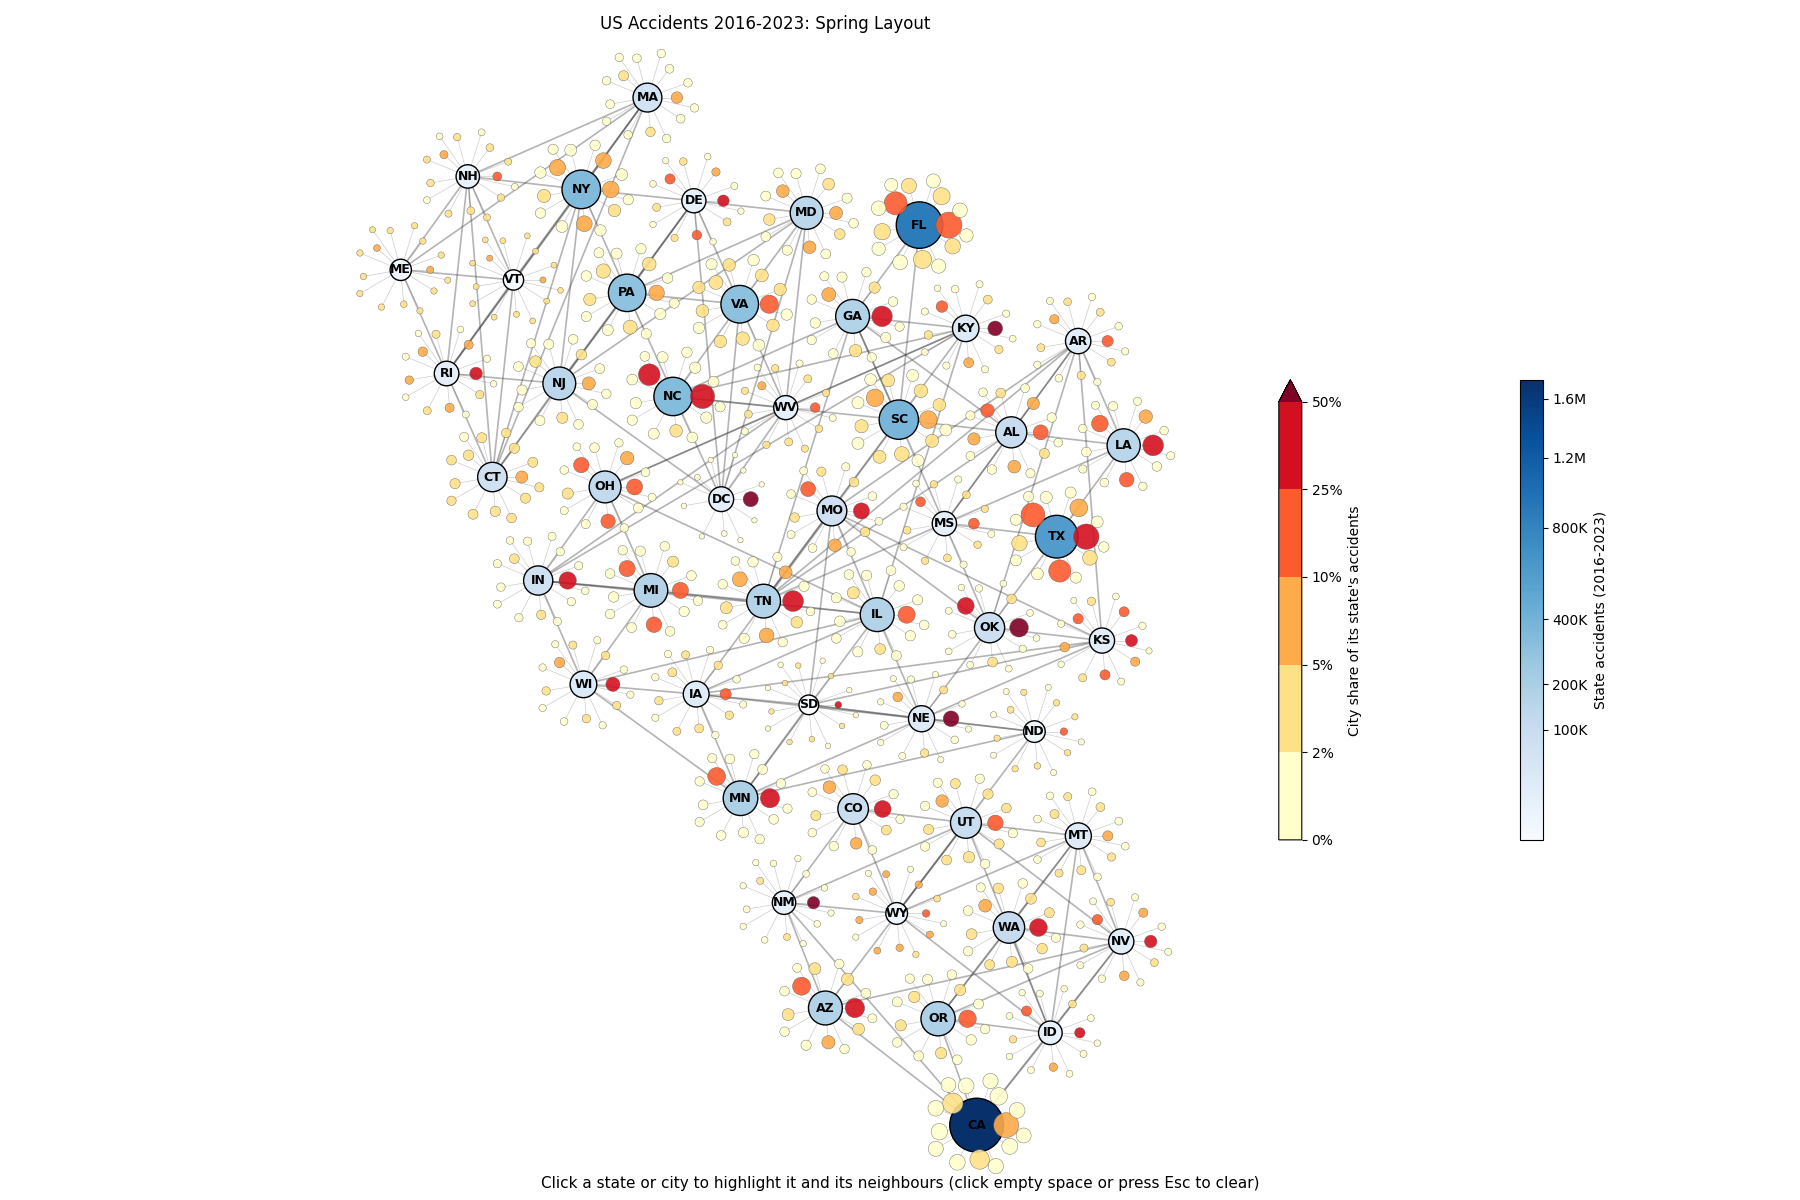

In [5]:
# ---------- layout: spring layout for hubs, then resolve cluster overlaps ----------
Gs = nx.Graph()
Gs.add_nodes_from(states)
Gs.add_edges_from(border_edges)
pos0 = nx.spring_layout(Gs, seed=42, k=0.5, iterations=300)

# city share of its state's total accidents (state totals include all cities, not just top N)
for n in cities:
    s = G.nodes[n]["state"]
    G.nodes[n]["share"] = G.nodes[n]["accidents"] / G.nodes[s]["accidents"]

by_state = {}
for c in cities:
    by_state.setdefault(G.nodes[c]["state"], []).append(c)

R0, R_STEP, PAD = 0.06, 0.018, 0.02      # R0 should be at least the hub's radius in data units

# cluster radius: hub + the area its city spiral covers
names = list(states)
rad = np.array([R0 + R_STEP * np.sqrt(len(by_state.get(s, []))) + PAD for s in names])

P0 = np.array([pos0[s] for s in names], dtype=float)
P = P0.copy()
rng = np.random.default_rng(0)

def push_apart(P, pull=0.0, max_iter=3000):
    for it in range(max_iter):
        moved = False
        for i in range(len(P)):
            for j in range(i + 1, len(P)):
                d = P[i] - P[j]
                dist = np.linalg.norm(d)
                need = rad[i] + rad[j]
                if dist < need:
                    if dist < 1e-9:                       # identical points: random direction
                        d = rng.normal(size=2); dist = np.linalg.norm(d)
                    shift = (need - dist) / 2 * d / dist
                    P[i] += shift
                    P[j] -= shift
                    moved = True
        if pull:
            P += pull * (P0 - P)                          # stay close to the spring structure
        if not moved and not pull:
            break
    return P

P = push_apart(P, pull=0.02, max_iter=200)    # spread while keeping the layout shape
P = push_apart(P, pull=0.0)                   # final pass: guarantees no overlaps

pos = {s: P[i] for i, s in enumerate(names)}

# check
d = np.linalg.norm(P[:, None] - P[None, :], axis=2)
np.fill_diagonal(d, np.inf)
# print("overlapping cluster pairs:", int((d < (rad[:, None] + rad[None, :]) - 1e-6).sum() // 2))

# ---------- cities on a golden-angle spiral around their hub ----------
golden = np.pi * (3 - np.sqrt(5))
for s, cs in by_state.items():
    cs = sorted(cs, key=lambda n: -G.nodes[n]["accidents"])
    for k, c in enumerate(cs):
        r = R0 + R_STEP * np.sqrt(k + 1)
        pos[c] = pos[s] + r * np.array([np.cos(k * golden), np.sin(k * golden)])

# ---------- encodings ----------
def size(lo, hi, nodelist):
    v = np.sqrt([G.nodes[x]["accidents"] for x in nodelist])
    return lo + (v - v.min()) / (v.max() - v.min() + 1e-9) * (hi - lo)

cmap_state = plt.cm.Blues
cmap_city = plt.cm.YlOrRd

# state hubs: colour = total accidents
st_counts = np.array([G.nodes[n]["accidents"] for n in states])
st_norm = PowerNorm(0.5, vmin=st_counts.min(), vmax=st_counts.max())
state_colors = cmap_state(st_norm(st_counts))

# cities: size = accident count, colour = share of its state's accidents (hotspot strength)
shares = np.array([G.nodes[n]["share"] for n in cities])
#added2 share bands: 0-2%, 2-5%, 5-10%, 10-25%, 25-50%, and 50%+ (the "extend" tier)
bounds = [0, 0.02, 0.05, 0.10, 0.25, 0.50]
ct_norm = BoundaryNorm(bounds, cmap_city.N, extend="max")
##added 
#ct_norm = PowerNorm(0.6, vmin=0, vmax=np.quantile(shares, 0.95))
city_colors = cmap_city(ct_norm(shares))

# ---------- draw ----------
fig, ax = plt.subplots(figsize=(18, 12))
nx.draw_networkx_edges(G, pos, edgelist=contain_edges, alpha=0.2, width=0.5, ax=ax)
nx.draw_networkx_edges(G, pos, edgelist=border_edges, alpha=0.4, width=1.2,
                       edge_color="#444", ax=ax)
nx.draw_networkx_nodes(G, pos, nodelist=states, node_size=size(200, 1500, states),
                       node_color=state_colors, edgecolors="black", linewidths=1, ax=ax)
nx.draw_networkx_nodes(G, pos, nodelist=cities, node_size=size(15, 350, cities),
                       node_color=city_colors, edgecolors="#555", linewidths=0.3,
                       alpha=0.9, ax=ax)

nx.draw_networkx_labels(G, pos, labels={s: s for s in states}, font_size=9,
                        font_weight="bold", ax=ax)

sm_s = plt.cm.ScalarMappable(norm=st_norm, cmap=cmap_state)
sm_c = plt.cm.ScalarMappable(norm=ct_norm, cmap=cmap_city)


cb_s = fig.colorbar(sm_s, ax=ax, shrink=0.4, pad=0.01, label="State accidents (2016-2023)")
cb_s.set_ticks([100_000, 200_000, 400_000, 800_000, 1_200_000, 1_600_000])
cb_s.ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x/1e6:.1f}M" if x >= 1e6 else f"{x/1e3:.0f}K"))

cb_c = fig.colorbar(sm_c, ax=ax, shrink=0.4, pad=0.06, extend="max",
                    ticks=bounds, spacing="uniform",
                    label="City share of its state's accidents")
cb_c.ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))


# ---------- fit the view to the data ----------
xs = np.array([p[0] for p in pos.values()])
ys = np.array([p[1] for p in pos.values()])
pad = 0.05
ax.set_xlim(xs.min() - pad, xs.max() + pad)
ax.set_ylim(ys.min() - pad, ys.max() + pad)
ax.set_aspect("equal", adjustable="box")

ax.set_title("US Accidents 2016-2023: Spring Layout", pad=4)
ax.axis("off")
plt.tight_layout()
plt.savefig("accidents_network1.png", dpi=200, bbox_inches="tight", pad_inches=0.1)
add_interaction(fig, ax, pos)
# plt.show()

# # ---------- hotspot ranking ----------
# rank = pd.DataFrame({
#     "city": [G.nodes[n]["label"] for n in cities],
#     "state": [G.nodes[n]["state"] for n in cities],
#     "accidents": [G.nodes[n]["accidents"] for n in cities],
#     "share": [G.nodes[n]["share"] for n in cities],
# })
# print(rank.sort_values("share", ascending=False).head(15).to_string(index=False))

nx.write_gexf(G, "accidents_network1.gexf")

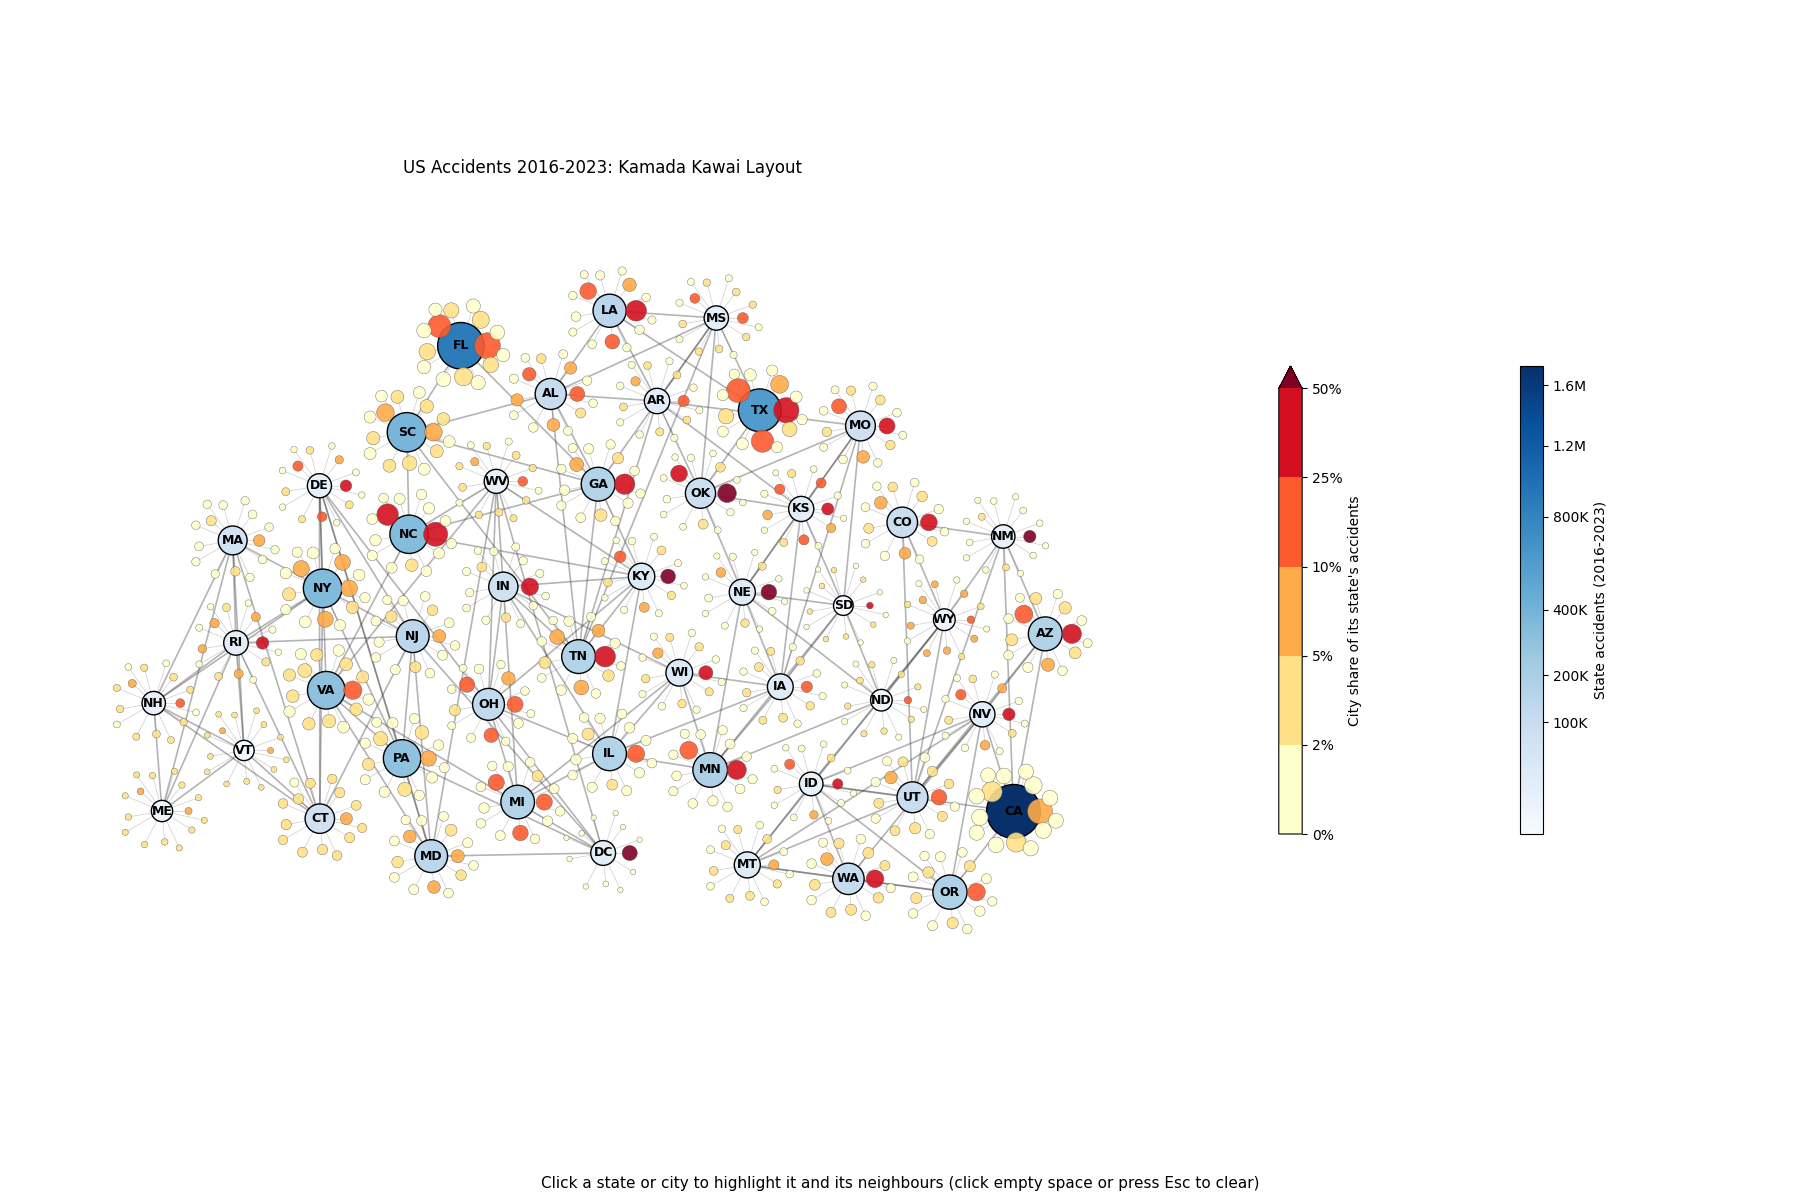

In [6]:
# ---------- layout: Kamada Kawai layout for hubs, then resolve cluster overlaps ----------
Gs = nx.Graph()
Gs.add_nodes_from(states)
Gs.add_edges_from(border_edges)
pos0 = nx.kamada_kawai_layout(Gs)

# city share of its state's total accidents (state totals include all cities, not just top N)
for n in cities:
    s = G.nodes[n]["state"]
    G.nodes[n]["share"] = G.nodes[n]["accidents"] / G.nodes[s]["accidents"]

by_state = {}
for c in cities:
    by_state.setdefault(G.nodes[c]["state"], []).append(c)

R0, R_STEP, PAD = 0.06, 0.018, 0.02      # R0 should be at least the hub's radius in data units

# cluster radius: hub + the area its city spiral covers
names = list(states)
rad = np.array([R0 + R_STEP * np.sqrt(len(by_state.get(s, []))) + PAD for s in names])

P0 = np.array([pos0[s] for s in names], dtype=float)
P = P0.copy()
rng = np.random.default_rng(0)

def push_apart(P, pull=0.0, max_iter=3000):
    for it in range(max_iter):
        moved = False
        for i in range(len(P)):
            for j in range(i + 1, len(P)):
                d = P[i] - P[j]
                dist = np.linalg.norm(d)
                need = rad[i] + rad[j]
                if dist < need:
                    if dist < 1e-9:                       # identical points: random direction
                        d = rng.normal(size=2); dist = np.linalg.norm(d)
                    shift = (need - dist) / 2 * d / dist
                    P[i] += shift
                    P[j] -= shift
                    moved = True
        if pull:
            P += pull * (P0 - P)                          # stay close to the spring structure
        if not moved and not pull:
            break
    return P

P = push_apart(P, pull=0.02, max_iter=200)    # spread while keeping the layout shape
P = push_apart(P, pull=0.0)                   # final pass: guarantees no overlaps

pos = {s: P[i] for i, s in enumerate(names)}

# check
d = np.linalg.norm(P[:, None] - P[None, :], axis=2)
np.fill_diagonal(d, np.inf)
# print("overlapping cluster pairs:", int((d < (rad[:, None] + rad[None, :]) - 1e-6).sum() // 2))

# ---------- cities on a golden-angle spiral around their hub ----------
golden = np.pi * (3 - np.sqrt(5))
for s, cs in by_state.items():
    cs = sorted(cs, key=lambda n: -G.nodes[n]["accidents"])
    for k, c in enumerate(cs):
        r = R0 + R_STEP * np.sqrt(k + 1)
        pos[c] = pos[s] + r * np.array([np.cos(k * golden), np.sin(k * golden)])

# ---------- encodings ----------
def size(lo, hi, nodelist):
    v = np.sqrt([G.nodes[x]["accidents"] for x in nodelist])
    return lo + (v - v.min()) / (v.max() - v.min() + 1e-9) * (hi - lo)

cmap_state = plt.cm.Blues
cmap_city = plt.cm.YlOrRd

# state hubs: colour = total accidents
st_counts = np.array([G.nodes[n]["accidents"] for n in states])
st_norm = PowerNorm(0.5, vmin=st_counts.min(), vmax=st_counts.max())
state_colors = cmap_state(st_norm(st_counts))

# cities: size = accident count, colour = share of its state's accidents (hotspot strength)
shares = np.array([G.nodes[n]["share"] for n in cities])
#share bands: 0-2%, 2-5%, 5-10%, 10-25%, 25-50%, and 50%+ (the "extend" tier)
bounds = [0, 0.02, 0.05, 0.10, 0.25, 0.50]
ct_norm = BoundaryNorm(bounds, cmap_city.N, extend="max")
city_colors = cmap_city(ct_norm(shares))

# ---------- draw ----------
fig, ax = plt.subplots(figsize=(18, 12))
nx.draw_networkx_edges(G, pos, edgelist=contain_edges, alpha=0.2, width=0.5, ax=ax)
nx.draw_networkx_edges(G, pos, edgelist=border_edges, alpha=0.4, width=1.2,
                       edge_color="#444", ax=ax)
nx.draw_networkx_nodes(G, pos, nodelist=states, node_size=size(200, 1500, states),
                       node_color=state_colors, edgecolors="black", linewidths=1, ax=ax)
nx.draw_networkx_nodes(G, pos, nodelist=cities, node_size=size(15, 350, cities),
                       node_color=city_colors, edgecolors="#555", linewidths=0.3,
                       alpha=0.9, ax=ax)

nx.draw_networkx_labels(G, pos, labels={s: s for s in states}, font_size=9,
                        font_weight="bold", ax=ax)

sm_s = plt.cm.ScalarMappable(norm=st_norm, cmap=cmap_state)
sm_c = plt.cm.ScalarMappable(norm=ct_norm, cmap=cmap_city)

cb_s = fig.colorbar(sm_s, ax=ax, shrink=0.4, pad=0.01, label="State accidents (2016-2023)")
cb_s.set_ticks([100_000, 200_000, 400_000, 800_000, 1_200_000, 1_600_000])
cb_s.ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x/1e6:.1f}M" if x >= 1e6 else f"{x/1e3:.0f}K"))
cb_c = fig.colorbar(sm_c, ax=ax, shrink=0.4, pad=0.06, extend="max",
                    ticks=bounds, spacing="uniform",
                    label="City share of its state's accidents")
cb_c.ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))

ax.set_title("US Accidents 2016-2023: Kamada Kawai Layout\n")
ax.set_aspect("equal")
ax.axis("off")
plt.tight_layout()
plt.savefig("accidents_network2.png", dpi=200)
add_interaction(fig, ax, pos)
# plt.show()

# # ---------- hotspot ranking ----------
# rank = pd.DataFrame({
#     "city": [G.nodes[n]["label"] for n in cities],
#     "state": [G.nodes[n]["state"] for n in cities],
#     "accidents": [G.nodes[n]["accidents"] for n in cities],
#     "share": [G.nodes[n]["share"] for n in cities],
# })
# print(rank.sort_values("share", ascending=False).head(15).to_string(index=False))

nx.write_gexf(G, "accidents_network2.gexf")

In [7]:
from math import radians, sin, cos, sqrt, atan2

def haversine_distance(u, v):
    row1 = centroids[centroids["State"] == u].iloc[0]
    row2 = centroids[centroids["State"] == v].iloc[0]
    lat1, lon1 = row1["Start_Lat"], row1["Start_Lng"]
    lat2, lon2 = row2["Start_Lat"], row2["Start_Lng"]

    lat1, lon1, lat2, lon2 = map(
        radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        sin(dlat / 2)**2
        + cos(lat1) * cos(lat2) * sin(dlon / 2)**2
    )

    c = 2 * atan2(sqrt(a), sqrt(1 - a))

    return 6371 * c   # km

In [8]:
# centroids= pd.read_csv("state_centroids.csv")
# centroids.info()
# u='MA'
# print(centroids[centroids["State"] == u])

In [9]:
# ---------------------------------------------------------
# 2. Planarize by removing edges from Kuratowski subgraphs
# ---------------------------------------------------------

def planarize_graph(G):
    Gp = G.copy()

    iteration = 0

    while True:
        is_planar, counterexample = nx.check_planarity(
            Gp,
            counterexample=True
        )

        if is_planar:
            print(f"Planar graph obtained after {iteration} edge removals.")
            break

        # Counterexample is a Kuratowski subgraph
        candidate_edges = list(counterexample.edges())
        # print(list(counterexample.edges()))

        # Choose an edge to remove.
        # Here: remove an edge with the highest degree-sum
        edge_to_remove = max(
            candidate_edges,
            key=lambda e: haversine_distance(e[0], e[1])
            )

        Gp.remove_edge(*edge_to_remove)

        iteration += 1

        # if iteration % 10 == 0:
        #     print(
        #         f"Iteration {iteration}: "
        #         f"{Gp.number_of_nodes()} nodes, "
        #         f"{Gp.number_of_edges()} edges"
        #     )

    return Gp

In [10]:
centroids= pd.read_csv("state_centroids.csv")

Gsnp = nx.Graph()
Gsnp.add_nodes_from(states)
Gsnp.add_edges_from(border_edges)

Gs = planarize_graph(Gsnp)

# print("Original edges :", Gsnp.number_of_edges())
# print("Planar edges   :", Gs.number_of_edges())

print(
    "Planar:",
    nx.check_planarity(Gs)[0]
)

Planar graph obtained after 30 edge removals.
Planar: True


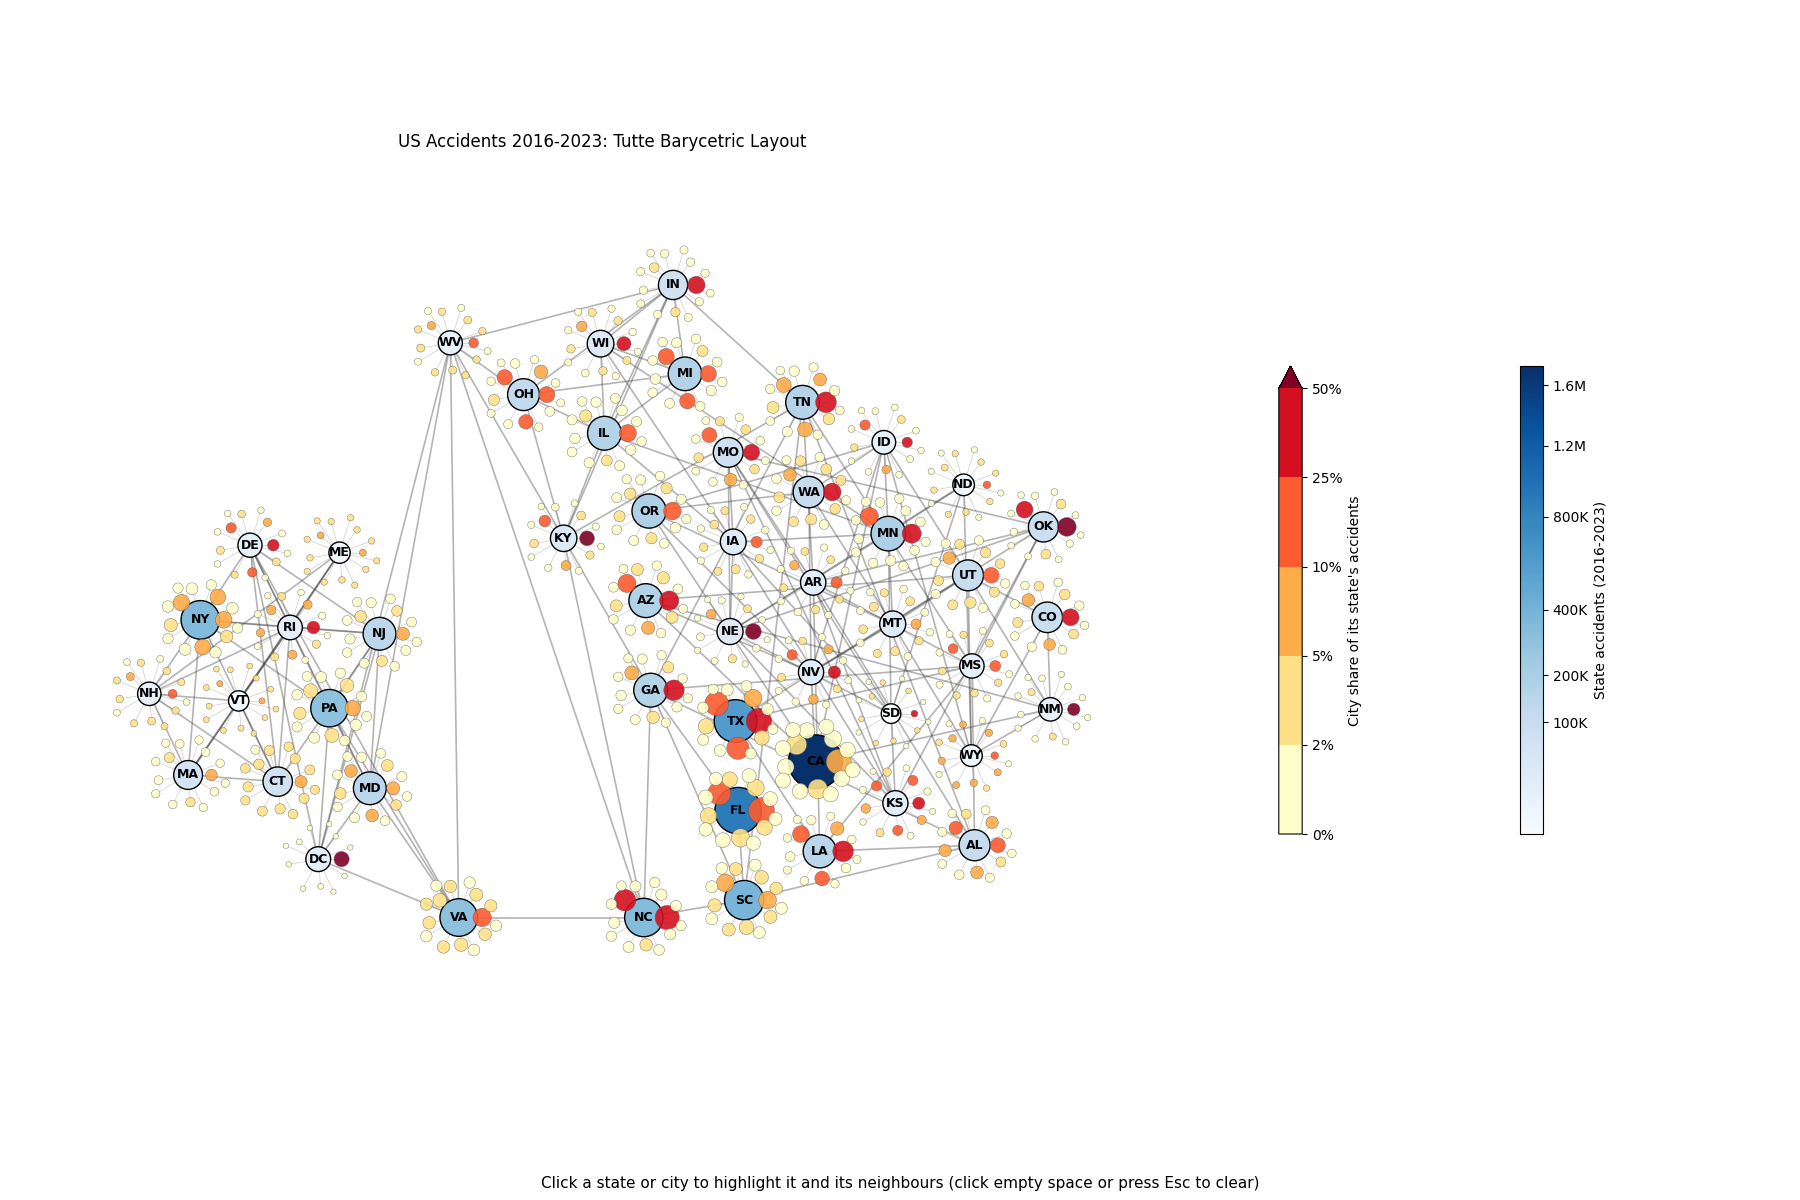

In [11]:
# ---------- layout: Tutte barycentric layout for state hubs ----------

# Tutte barycentric embedding requires a planar graph
is_planar, embedding = nx.check_planarity(Gs)

if not is_planar:
    raise ValueError(
        "The state-border graph is not planar, so a standard Tutte "
        "barycentric embedding cannot be constructed."
    )

#  city share of its state's total accidents (state totals include all cities, not just top N)
for n in cities:
    s = G.nodes[n]["state"]
    G.nodes[n]["share"] = G.nodes[n]["accidents"] / G.nodes[s]["accidents"]

# ---------------------------------------------------------
# Extract faces
# ---------------------------------------------------------

visited_darts = set()
faces = []
for u, v in embedding.edges():
    if (u, v) in visited_darts:
        continue
    face = embedding.traverse_face(
        u,
        v,
        visited_darts
    )
    faces.append(face)
# print("Number of faces:", len(faces))


# ---------------------------------------------------------
# Select outer face
# ---------------------------------------------------------
boundary = max(
    faces,
    key=len
)

# print("Tutte outer boundary:")
# print(boundary)

# print("Boundary size:", len(boundary))


def tutte_layout(G, boundary, radius=1.0):
    """
    Tutte barycentric layout.

    Boundary vertices are fixed on a circle.
    Every interior vertex is placed at the average
    position of its neighboring vertices.
    """
    pos = {}

    # -------------------------------------------------
    # 1. Fix boundary vertices on a circle
    # -------------------------------------------------
    m = len(boundary)
    for i, node in enumerate(boundary):
        angle = 2 * np.pi * i / m
        pos[node] = np.array([
            radius * np.cos(angle),
            radius * np.sin(angle)
        ])

    # -------------------------------------------------
    # 2. Interior vertices
    # -------------------------------------------------
    interior = [
        node for node in G.nodes
        if node not in boundary
    ]
    n = len(interior)
    if n == 0:
        return pos
    index = {
        node: i
        for i, node in enumerate(interior)
    }

    # -------------------------------------------------
    # 3. Construct barycentric equations
    #
    # x_i = average(x_neighbors)
    # y_i = average(y_neighbors)
    # -------------------------------------------------

    A = np.zeros((n, n))
    bx = np.zeros(n)
    by = np.zeros(n)
    for node in interior:
        i = index[node]
        neighbors = list(G.neighbors(node))
        degree = len(neighbors)
        # x_i coefficient
        A[i, i] = 1.0
        for neighbor in neighbors:
            weight = 1.0 / degree
            if neighbor in index:
                # Interior neighbor
                j = index[neighbor]
                A[i, j] -= weight
            else:
                # Boundary neighbor
                bx[i] += weight * pos[neighbor][0]
                by[i] += weight * pos[neighbor][1]

    # -------------------------------------------------
    # 4. Solve the barycentric system
    # -------------------------------------------------
    x = np.linalg.solve(A, bx)
    y = np.linalg.solve(A, by)

    # -------------------------------------------------
    # 5. Store positions
    # -------------------------------------------------
    for node in interior:
        i = index[node]
        pos[node] = np.array([
            x[i],
            y[i]
        ])
    return pos

# Generate Tutte positions for state hubs
pos0 = tutte_layout(Gs, boundary, radius=1.0)

# ---------- group cities by state ----------
by_state = {}
for c in cities:
    s = G.nodes[c]["state"]
    by_state.setdefault(s, []).append(c)

# ---------- cluster radius ----------
R0 = 0.06
R_STEP = 0.018
PAD = 0.02
names = list(states)
rad = np.array([
    R0
    + R_STEP * np.sqrt(len(by_state.get(s, [])))
    + PAD
    for s in names
])

# ---------- resolve overlapping state clusters ----------
P0 = np.array([
    pos0[s]
    for s in names
], dtype=float)
P = P0.copy()
rng = np.random.default_rng(0)

def push_apart(P, pull=0.0, max_iter=3000):
    for it in range(max_iter):
        moved = False
        for i in range(len(P)):
            for j in range(i + 1, len(P)):
                d = P[i] - P[j]
                dist = np.linalg.norm(d)
                need = rad[i] + rad[j]
                if dist < need:
                    if dist < 1e-9:
                        d = rng.normal(size=2)
                        dist = np.linalg.norm(d)
                    shift = (
                        (need - dist) / 2
                        * d / dist
                    )
                    P[i] += shift
                    P[j] -= shift
                    moved = True
        # Keep state positions reasonably close
        # to the original Tutte embedding
        if pull:
            P += pull * (P0 - P)
        if not moved and not pull:
            break
    return P

# First pass: spread while approximately preserving
# Tutte structure
P = push_apart(
    P,
    pull=0.02,
    max_iter=200
)
# Final pass: remove remaining overlaps
P = push_apart(
    P,
    pull=0.0
)
# Final state positions
pos = {
    s: P[i]
    for i, s in enumerate(names)
}

# ---------- check cluster overlaps ----------
d = np.linalg.norm(
    P[:, None] - P[None, :],
    axis=2
)
np.fill_diagonal(d, np.inf)
# print(
#     "overlapping cluster pairs:",
#     int(
#         (
#             d
#             < (
#                 rad[:, None]
#                 + rad[None, :]
#             )
#             - 1e-6
#         ).sum()
#         // 2
#     )
# )

# ---------- cities on golden-angle spiral ----------
golden = np.pi * (3 - np.sqrt(5))
for s, cs in by_state.items():
    cs = sorted(
        cs,
        key=lambda n: -G.nodes[n]["accidents"]
    )
    for k, c in enumerate(cs):
        r = (
            R0
            + R_STEP * np.sqrt(k + 1)
        )
        pos[c] = (
            pos[s]
            + r
            * np.array([
                np.cos(k * golden),
                np.sin(k * golden)
            ])
        )

# ---------- encodings ----------
def size(lo, hi, nodelist):
    v = np.sqrt([G.nodes[x]["accidents"] for x in nodelist])
    return lo + (v - v.min()) / (v.max() - v.min() + 1e-9) * (hi - lo)

cmap_state = plt.cm.Blues
cmap_city = plt.cm.YlOrRd

# state hubs: colour = total accidents
st_counts = np.array([G.nodes[n]["accidents"] for n in states])
st_norm = PowerNorm(0.5, vmin=st_counts.min(), vmax=st_counts.max())
state_colors = cmap_state(st_norm(st_counts))

# cities: size = accident count, colour = share of its state's accidents (hotspot strength)
shares = np.array([G.nodes[n]["share"] for n in cities])
#added2 share bands: 0-2%, 2-5%, 5-10%, 10-25%, 25-50%, and 50%+ (the "extend" tier)
bounds = [0, 0.02, 0.05, 0.10, 0.25, 0.50]
ct_norm = BoundaryNorm(bounds, cmap_city.N, extend="max")
city_colors = cmap_city(ct_norm(shares))

# ---------- draw ----------
fig, ax = plt.subplots(figsize=(18, 12))
nx.draw_networkx_edges(G, pos, edgelist=contain_edges, alpha=0.2, width=0.5, ax=ax)
nx.draw_networkx_edges(G, pos, edgelist=border_edges, alpha=0.4, width=1.2,
                       edge_color="#444", ax=ax)
nx.draw_networkx_nodes(G, pos, nodelist=states, node_size=size(200, 1500, states),
                       node_color=state_colors, edgecolors="black", linewidths=1, ax=ax)
nx.draw_networkx_nodes(G, pos, nodelist=cities, node_size=size(15, 350, cities),
                       node_color=city_colors, edgecolors="#555", linewidths=0.3,
                       alpha=0.9, ax=ax)

nx.draw_networkx_labels(G, pos, labels={s: s for s in states}, font_size=9,
                        font_weight="bold", ax=ax)

sm_s = plt.cm.ScalarMappable(norm=st_norm, cmap=cmap_state)
sm_c = plt.cm.ScalarMappable(norm=ct_norm, cmap=cmap_city)

cb_s = fig.colorbar(sm_s, ax=ax, shrink=0.4, pad=0.01, label="State accidents (2016-2023)")
cb_s.set_ticks([100_000, 200_000, 400_000, 800_000, 1_200_000, 1_600_000])
cb_s.ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x/1e6:.1f}M" if x >= 1e6 else f"{x/1e3:.0f}K"))
cb_c = fig.colorbar(sm_c, ax=ax, shrink=0.4, pad=0.06, extend="max",
                    ticks=bounds, spacing="uniform",
                    label="City share of its state's accidents")
cb_c.ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))

ax.set_title("US Accidents 2016-2023: Tutte Barycetric Layout\n")
ax.set_aspect("equal")
ax.axis("off")
plt.tight_layout()
plt.savefig("accidents_network3.png", dpi=200)
add_interaction(fig, ax, pos)
# plt.show()

# # ---------- hotspot ranking ----------
# rank = pd.DataFrame({
#     "city": [G.nodes[n]["label"] for n in cities],
#     "state": [G.nodes[n]["state"] for n in cities],
#     "accidents": [G.nodes[n]["accidents"] for n in cities],
#     "share": [G.nodes[n]["share"] for n in cities],
# })
# print(rank.sort_values("share", ascending=False).head(15).to_string(index=False))

nx.write_gexf(G, "accidents_network3.gexf")